In [1]:
import os, glob
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
geo = 'GSE159478'
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'vertebrate', geo)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'cancer', 'vertebrate', geo)

In [3]:
df = pd.read_csv(os.path.join(pth_data, 'summary.csv'), index_col = 0)
labels_dict = df.Signature.dropna().to_dict(); labels_dict

{'GSE162534': 'Gast', 'GSE229103': 'pSom', 'rRNAModifications': 'Crest'}

In [4]:
adata = sc.read_h5ad(os.path.join(pth_in, 'trajectory.h5ad'))
adata

AnnData object with n_obs × n_vars = 1242 × 26602
    obs: 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 't', 'seg', 'edge', 'milestones'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'celltype_colors', 'graph', 'leiden', 'leiden_colors', 'log1p', 'milestones_colors', 'neighbors', 'pca', 'pseudotime_list', 'sample_colors', 'seg_colors', 'umap'
    obsm: 'X_R', 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [5]:
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src = lambda fn: os.path.split(fn)[1].replace('.csv', '')
feat_dict = {get_src(fn) : pd.read_csv(fn) for fn in feat_fn}

# module signatures
g_ref = feat_dict['union'].mmusculus.drop_duplicates()
g_ref = g_ref.loc[g_ref.isin(adata.var_names)].copy()
for src, df_src in feat_dict.items():
    if src != 'union':
        g = df_src.mmusculus.drop_duplicates()
        g = g.loc[g.isin(adata.var_names)].copy()
        sc.tl.score_genes(adata,
                          gene_list = g,
                          score_name = src,
                          ctrl_as_ref = False,
                          gene_pool = g_ref,
                          random_state = 1234)
        print(src, g.size, g_ref.size)

GSE162534 75 223
GSE229103 90 223
rRNAModifications 101 223


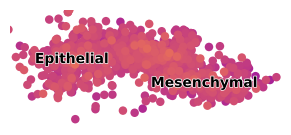

In [ ]:
s = 150
fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.umap(adata, dimensions = [1, 0], color = 'GSE162534', size = s,
           cmap = 'plasma', vmin = -.4, vmax = .4,
           colorbar_loc = None, frameon = False, show = False,
           ax = ax)
sc.pl.umap(adata, dimensions = [1, 0], color = 'celltype', alpha = 0,
           legend_loc = 'on data', legend_fontoutline = 1, frameon = False,
           show = False, ax = ax)
ax.invert_xaxis(); ax.set_title('')
xlim = ax.get_xlim(); ylim = ax.get_ylim()
ax.set_xlim((xlim[0] - 1.5, xlim[1] + .45))
ax.set_ylim((ylim[0] + 3.9, ylim[1] - 1.35))

pos_dict = {
    'Epithelial'  : (1.2, -.15),
    'Mesenchymal' : (.1, 0)}

for label in ax.texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in pos_dict:
        dx, dy = pos_dict[_label_]
        label.set_position([x + dx, y + dy])

# fn = os.path.join(pth_out, 'trajectory.pdf')
# plt.savefig(fn, bbox_inches = 'tight')
plt.show()

In [ ]:
# adata.write(os.path.join(pth_in, 'signatures.h5ad'))